Wczytujemy pojedynczy obraz wykresu punktowego i definiujemy ręczną konfigurację. Na wejściu potrzebujemy dwa elementy: obszar danych na obrazie (`plot_bbox`) oraz kalibrację osi X i Y. To jest kontrakt wejściowy dla dalszej detekcji punktów.

In [12]:
from pathlib import Path
import sys
import json
import math

import cv2
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.scatter_detection.data.utils.constants import X_MIN, X_MAX, Y_MIN, Y_MAX
IMAGE_ID = "plot_001"
DATA_DIR = PROJECT_ROOT / "src" /"scatter_detection" /"data" / "generated_data"
IMAGE_PATH = DATA_DIR / "images" / f"{IMAGE_ID}.png"
METADATA_PATH = DATA_DIR / "metadata" / f"{IMAGE_ID}_gt.json"
CONFIG_DIR = Path.cwd().resolve()
CONFIG_PATH = CONFIG_DIR / f"{IMAGE_ID}_config.json"

print(f"Project root: {PROJECT_ROOT}")
print(f"Image path:   {IMAGE_PATH}")

Project root: C:\Users\pawel\OneDrive - Politechnika Wroclawska\Desktop\zadanie_rekrutacyjne_solvro
Image path:   C:\Users\pawel\OneDrive - Politechnika Wroclawska\Desktop\zadanie_rekrutacyjne_solvro\src\scatter_detection\data\generated_data\images\plot_001.png


Najpierw odczytujemy wymiary zdjęcia i jego metadane. Oś X i Y są kalibrowane z wartościami z `src.scatter_detection.constants`, więc nie wpisujemy ich na sztywno. W tej chwili kontrolujemy tylko geometrię: gdzie leży wykres i jakie są przypisane wartości do pikseli.

In [13]:
METADATA = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
IMAGE_WIDTH = METADATA["width"]
IMAGE_HEIGHT = METADATA["height"]

subplot_left = plt.rcParams["figure.subplot.left"]
subplot_right = plt.rcParams["figure.subplot.right"]
subplot_bottom = plt.rcParams["figure.subplot.bottom"]
subplot_top = plt.rcParams["figure.subplot.top"]

px1 = math.floor(subplot_left * IMAGE_WIDTH)
px2 = math.ceil(subplot_right * IMAGE_WIDTH)

py1 = math.ceil((1.0 - subplot_bottom) * IMAGE_HEIGHT)
py2 = math.floor((1.0 - subplot_top) * IMAGE_HEIGHT)

CONFIG = {
    "image_id": IMAGE_ID,
    "plot_bbox": [px1, py2, px2, py1],
    "calibration": {
        "x_axis": {"px1": px1, "val1": X_MIN, "px2": px2, "val2": X_MAX},
        "y_axis": {"py1": py1, "val1": Y_MIN, "py2": py2, "val2": Y_MAX}
    },
}

Walidacja sprawdza, czy obszar wykresu jest poprawny i czy kalibracja ma sens. Jeśli coś jest źle ustawione, lepiej przerwać od razu niż dopuścić do błędnych wyników w kolejnych etapach.

In [14]:
def validate_configuration(config: dict, image):
    """Validate the manual geometry required by the extraction pipeline."""
    if image is None:
        raise FileNotFoundError(f"Could not read image for image_id: {config['image_id']}")

    image_height, image_width = image.shape[:2]
    xmin, ymin, xmax, ymax = config["plot_bbox"]
    if not (0 <= xmin < xmax <= image_width and 0 <= ymin < ymax <= image_height):
        raise ValueError("plot_bbox is outside the image or has invalid bounds.")

    x_axis = config["calibration"]["x_axis"]
    y_axis = config["calibration"]["y_axis"]
    if x_axis["px1"] == x_axis["px2"] or x_axis["val1"] == x_axis["val2"]:
        raise ValueError("X-axis calibration must have two distinct pixels and values.")
    if y_axis["py1"] == y_axis["py2"] or y_axis["val1"] == y_axis["val2"]:
        raise ValueError("Y-axis calibration must have two distinct pixels and values.")

    return image_width, image_height

IMAGE = cv2.imread(str(IMAGE_PATH))
IMAGE_WIDTH, IMAGE_HEIGHT = validate_configuration(CONFIG, IMAGE)
print(f"Validated image size: {IMAGE_WIDTH} × {IMAGE_HEIGHT} px")

Validated image size: 685 × 591 px


Na obrazie rysujemy czerwony prostokąt obejmujący wnętrze wykresu. Niebieskie punkty pokazują punkty kalibracyjne. Jeśli całość wygląda sensownie, zapisujemy konfigurację razem z danymi testowymi.

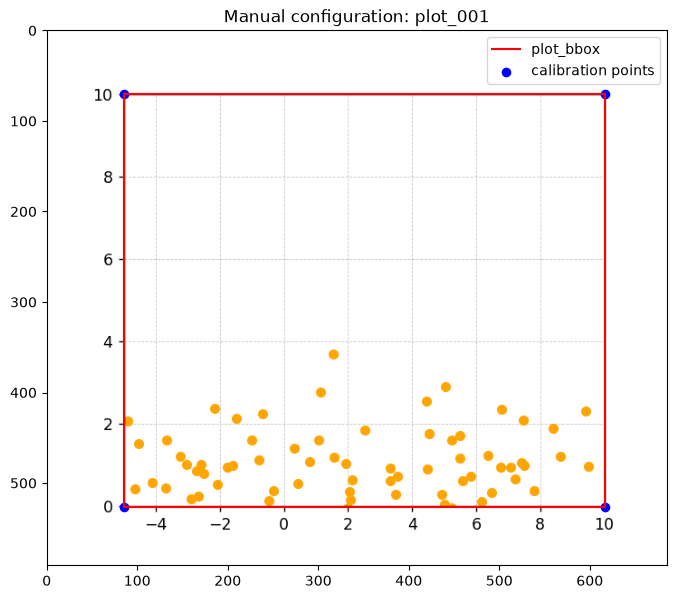

Configuration saved to: C:\Users\pawel\OneDrive - Politechnika Wroclawska\Desktop\zadanie_rekrutacyjne_solvro\experiments\plot_001_config.json


In [15]:
xmin, ymin, xmax, ymax = CONFIG["plot_bbox"]
x_axis = CONFIG["calibration"]["x_axis"]
y_axis = CONFIG["calibration"]["y_axis"]
image_rgb = cv2.cvtColor(IMAGE, cv2.COLOR_BGR2RGB)

figure, axis = plt.subplots(figsize=(8, 8))
axis.imshow(image_rgb)
axis.plot([xmin, xmax, xmax, xmin, xmin], [ymin, ymin, ymax, ymax, ymin], color="red", label="plot_bbox")
axis.scatter(
    [x_axis["px1"], x_axis["px1"], x_axis["px2"], x_axis["px2"]],
    [y_axis["py1"], y_axis["py2"], y_axis["py1"], y_axis["py2"]],
    color="blue", s=35, label="calibration points",
)
axis.set_title(f"Manual configuration: {IMAGE_ID}")
axis.legend()
axis.set_xlim(0, IMAGE_WIDTH)
axis.set_ylim(IMAGE_HEIGHT, 0)
plt.show()

CONFIG_DIR.mkdir(parents=True, exist_ok=True)
with CONFIG_PATH.open("w", encoding="utf-8") as config_file:
    json.dump(CONFIG, config_file, indent=2)
print(f"Configuration saved to: {CONFIG_PATH}")

W tym miejscu wycinamy tylko obszar wykresu z pełnego obrazu. Nie zmieniamy jeszcze punktów, tylko odseparowujemy właściwy fragment danych. Później centroidy wykryte w tym cropie będzie można z powrotem zmapować na oryginalne współrzędne obrazu.

In [16]:
def isolate_plot_area(image, config: dict):
    """Crop the configured plot area from the full OpenCV image."""
    if image is None:
        raise ValueError("Cannot isolate a plot from an empty image.")

    xmin, ymin, xmax, ymax = config["plot_bbox"]
    image_height, image_width = image.shape[:2]
    if not (0 <= xmin < xmax <= image_width and 0 <= ymin < ymax <= image_height):
        raise ValueError("plot_bbox is outside the image or has invalid bounds.")

    plot_image = image[ymin:ymax, xmin:xmax].copy()
    expected_height = ymax - ymin
    expected_width = xmax - xmin
    if plot_image.shape[:2] != (expected_height, expected_width):
        raise RuntimeError("The isolated plot has an unexpected shape.")

    return plot_image


PLOT_IMAGE = isolate_plot_area(IMAGE, CONFIG)
PLOT_HEIGHT, PLOT_WIDTH = PLOT_IMAGE.shape[:2]
print(f"Isolated plot size: {PLOT_WIDTH} × {PLOT_HEIGHT} px")

Isolated plot size: 532 × 456 px


Lewy panel pokazuje pełny obraz i czerwony obszar wykresu. Prawy panel pokazuje dokładnie ten fragment, który trafia dalej do detekcji.

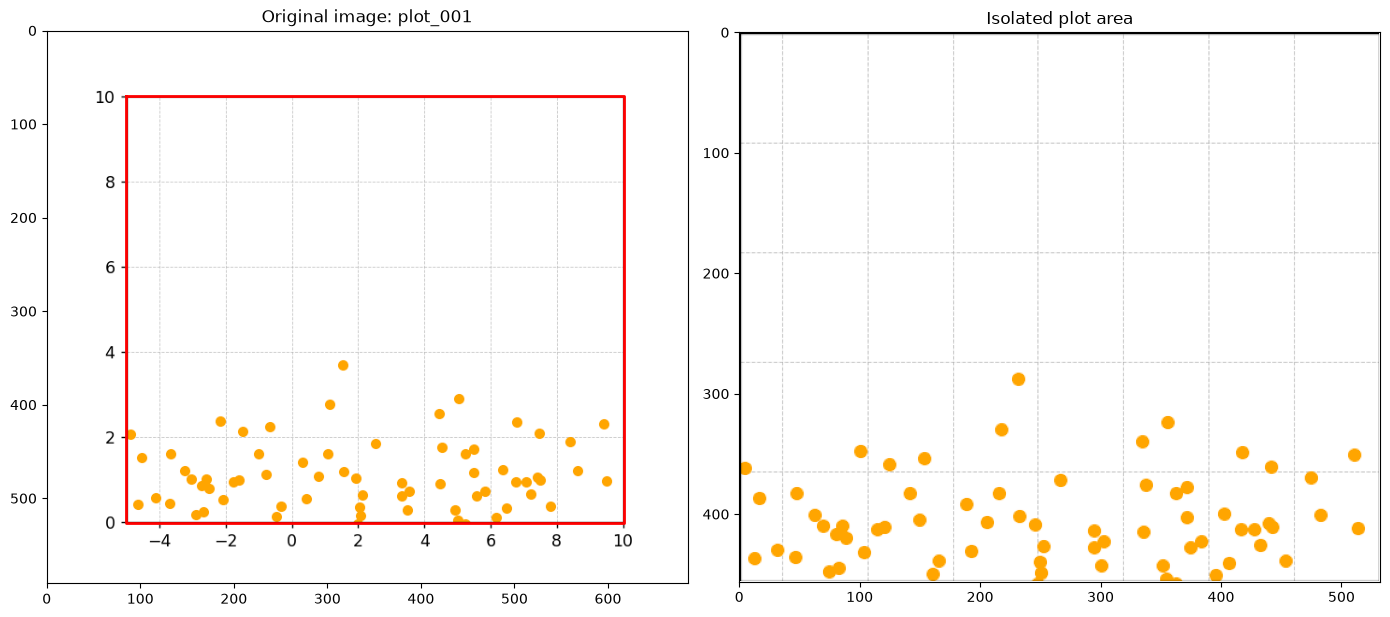

In [17]:
plot_image_rgb = cv2.cvtColor(PLOT_IMAGE, cv2.COLOR_BGR2RGB)
figure, (full_axis, plot_axis) = plt.subplots(1, 2, figsize=(14, 6))

full_axis.imshow(cv2.cvtColor(IMAGE, cv2.COLOR_BGR2RGB))
full_axis.plot(
    [xmin, xmax, xmax, xmin, xmin],
    [ymin, ymin, ymax, ymax, ymin],
    color="red",
    linewidth=2,
)
full_axis.set_title(f"Original image: {IMAGE_ID}")
full_axis.set_xlim(0, IMAGE_WIDTH)
full_axis.set_ylim(IMAGE_HEIGHT, 0)

plot_axis.imshow(plot_image_rgb)
plot_axis.set_title("Isolated plot area")
plot_axis.set_xlim(0, PLOT_WIDTH)
plot_axis.set_ylim(PLOT_HEIGHT, 0)

plt.tight_layout()
plt.show()

Wykrywamy punkty bez zakładania konkretnego koloru. Najpierw tworzymy maskę pikseli odstających od jasnego tła, potem usuwamy cienkie fragmenty siatki i zostawiamy tylko małe, ciemne komponenty. Każdy taki komponent jest traktowany jako jeden marker.

In [18]:
def create_color_independent_mask(plot_image, background_threshold=245):
    """Create a foreground mask"""
    if plot_image is None or plot_image.size == 0:
        raise ValueError("Cannot create a mask from an empty plot image.")

    grayscale = cv2.cvtColor(plot_image, cv2.COLOR_BGR2GRAY)
    _, foreground_mask = cv2.threshold(
        grayscale,
        background_threshold,
        255,
        cv2.THRESH_BINARY_INV,
    )

    # Opening removes thin grid/axis fragments while preserving marker blobs.
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    return cv2.morphologyEx(foreground_mask, cv2.MORPH_OPEN, kernel)


def detect_points(plot_image, config, min_area=8, max_area=500):
    """Detect marker centroids and return local and original-image coordinates."""
    mask = create_color_independent_mask(plot_image)
    number_of_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        mask,
        connectivity=8,
    )

    xmin, ymin, _, _ = config["plot_bbox"]
    detected_points = []
    for label in range(1, number_of_labels):
        area = int(stats[label, cv2.CC_STAT_AREA])
        width = int(stats[label, cv2.CC_STAT_WIDTH])
        height = int(stats[label, cv2.CC_STAT_HEIGHT])
        if not (min_area <= area <= max_area):
            continue
        if width == 0 or height == 0:
            continue
        aspect_ratio = width / height

        # aspect ratio powinien być w przybliżeniu równy jeden
        if abs(aspect_ratio - 1) > 0.5:
            continue
        
        x_local, y_local = centroids[label]
        detected_points.append(
            {
                "x_local": float(x_local),
                "y_local": float(y_local),
                "x_px": float(x_local + xmin),
                "y_px": float(y_local + ymin),
                "area": area,
            }
        )
    return mask, detected_points

POINT_MASK, DETECTED_POINTS = detect_points(PLOT_IMAGE, CONFIG)
print(f"Detected points: {len(DETECTED_POINTS)}")

Detected points: 47


Na lewym panelu widać maskę po odfiltrowaniu tła, na prawym — centroidy wykrytych obiektów położone na wyciętym wykresie.

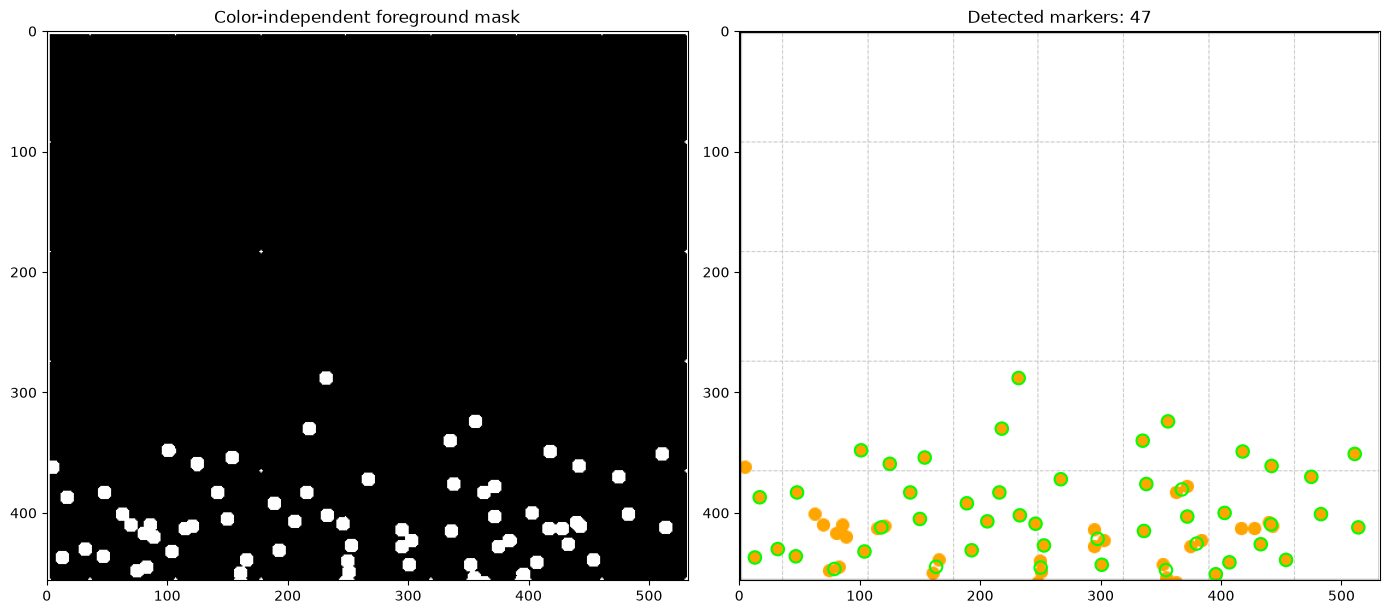

In [19]:
figure, (mask_axis, detection_axis) = plt.subplots(1, 2, figsize=(14, 6))
mask_axis.imshow(POINT_MASK, cmap="gray")
mask_axis.set_title("Color-independent foreground mask")
mask_axis.set_xlim(0, PLOT_WIDTH)
mask_axis.set_ylim(PLOT_HEIGHT, 0)

detection_axis.imshow(cv2.cvtColor(PLOT_IMAGE, cv2.COLOR_BGR2RGB))
if DETECTED_POINTS:
    detection_axis.scatter(
        [point["x_local"] for point in DETECTED_POINTS],
        [point["y_local"] for point in DETECTED_POINTS],
        facecolors="none",
        edgecolors="lime",
        s=80,
        linewidths=1.5,
    )
detection_axis.set_title(f"Detected markers: {len(DETECTED_POINTS)}")
detection_axis.set_xlim(0, PLOT_WIDTH)
detection_axis.set_ylim(PLOT_HEIGHT, 0)
plt.tight_layout()
plt.show()

Tutaj przeliczamy współrzędne pikselowe centroidów na rzeczywiste wartości osi wykresu. Oś Y w obrazie rośnie w dół, więc przy mapowaniu trzeba odwrócić kierunek, żeby uzyskać sensowny układ matematyczny.

In [20]:
def pixel_to_value(point, calibration):
    """Convert one detected point from image pixels to plot values."""
    x_axis = calibration["x_axis"]
    y_axis = calibration["y_axis"]
    x_px = point["x_px"]
    y_px = point["y_px"]

    x_value = x_axis["val1"] + (
        (x_px - x_axis["px1"]) / (x_axis["px2"] - x_axis["px1"])
        * (x_axis["val2"] - x_axis["val1"])
    )
    y_value = y_axis["val1"] + (
        (y_axis["py1"] - y_px) / (y_axis["py1"] - y_axis["py2"])
        * (y_axis["val2"] - y_axis["val1"])
    )

    converted_point = dict(point)
    converted_point["x"] = float(x_value)
    converted_point["y"] = float(y_value)
    return converted_point


EXTRACTED_POINTS = [
    pixel_to_value(point, CONFIG["calibration"])
    for point in DETECTED_POINTS
]
print(f"Converted points: {len(EXTRACTED_POINTS)}")
print(EXTRACTED_POINTS[:3])

Converted points: 47
[{'x_local': 232.0, 'y_local': 288.0, 'x_px': 317.0, 'y_px': 358.0, 'area': 109, 'x': 1.5413533834586461, 'y': 3.6842105263157894}, {'x_local': 356.0, 'y_local': 324.0, 'x_px': 441.0, 'y_px': 394.0, 'area': 109, 'x': 5.037593984962406, 'y': 2.8947368421052633}, {'x_local': 218.0, 'y_local': 330.0, 'x_px': 303.0, 'y_px': 400.0, 'area': 109, 'x': 1.1466165413533833, 'y': 2.7631578947368425}]


Lewy panel to piksele, prawy panel to już wartości osi X/Y. W `EXTRACTED_POINTS` zostają zapisane zarówno współrzędne pikselowe, jak i przeliczone wartości matematyczne.

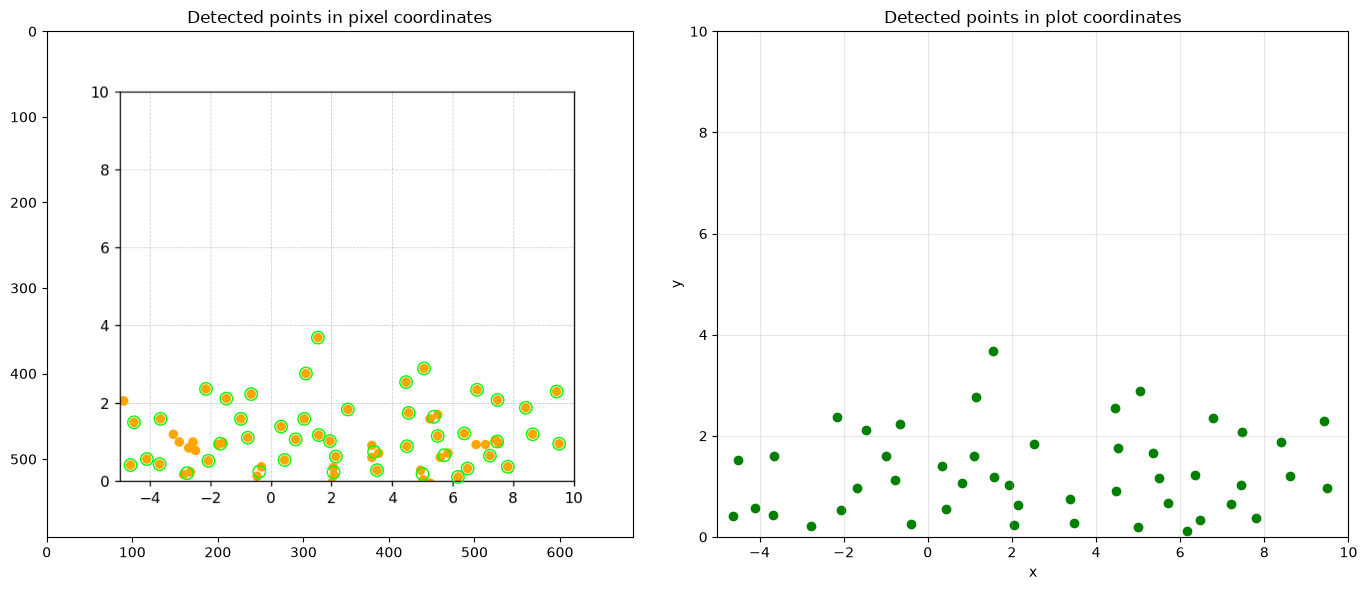

In [21]:
figure, (pixel_axis, value_axis) = plt.subplots(1, 2, figsize=(14, 6))
pixel_axis.imshow(cv2.cvtColor(IMAGE, cv2.COLOR_BGR2RGB))
if EXTRACTED_POINTS:
    pixel_axis.scatter(
        [point["x_px"] for point in EXTRACTED_POINTS],
        [point["y_px"] for point in EXTRACTED_POINTS],
        facecolors="none",
        edgecolors="lime",
        s=80,
    )
pixel_axis.set_title("Detected points in pixel coordinates")
pixel_axis.set_xlim(0, IMAGE_WIDTH)
pixel_axis.set_ylim(IMAGE_HEIGHT, 0)

value_axis.scatter(
    [point["x"] for point in EXTRACTED_POINTS],
    [point["y"] for point in EXTRACTED_POINTS],
    color="green",
)
value_axis.set_title("Detected points in plot coordinates")
value_axis.set_xlim(X_MIN, X_MAX)
value_axis.set_ylim(Y_MIN, Y_MAX)
value_axis.set_xlabel("x")
value_axis.set_ylabel("y")
value_axis.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()